In [13]:
# Loading ecommerce_dataset

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [15]:
sales_data = pd.read_csv('ecommerce_sales.csv')
sales_data.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


## 1.CLEANING SALES DATA

### Numbers of rows and column in dataset

In [16]:
sales_data.shape

(5000, 12)

#### what are the columns or fields provided in the dataset?

In [17]:
sales_data.columns

Index(['order_id', 'order_date', 'customer_id', 'product_category', 'region',
       'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days',
       'customer_rating', 'revenue'],
      dtype='object')

#### Information about the sales data 

In [18]:
sales_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   object 
 2   customer_id       5000 non-null   int64  
 3   product_category  5000 non-null   object 
 4   region            5000 non-null   object 
 5   quantity          5000 non-null   int64  
 6   unit_price        5000 non-null   float64
 7   discount          5000 non-null   float64
 8   payment_method    5000 non-null   object 
 9   delivery_days     5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  revenue           5000 non-null   float64
dtypes: float64(4), int64(4), object(4)
memory usage: 468.9+ KB


#### General statistics 

In [19]:
sales_data.describe()

,order_id,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,1505.701200,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
std,1443.520003,290.836902,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219
min,10001.000000,1000.000000,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,11250.750000,1253.000000,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,12500.500000,1510.000000,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,13750.250000,1761.000000,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,15000.000000,1999.000000,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000


### Checking if the data contains duplicate values


In [20]:
sales_data.duplicated().sum()

np.int64(0)

In [21]:
sales_data.loc[sales_data.duplicated()]

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue


##### There are no duplicate data in the dataset.

### Check if the data consists of any null value

In [22]:
sales_data.isnull().sum()

order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64

#### There are no null values in the dataset

In [23]:
sales_data.isna().sum()

order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64

In [24]:
# There are no missing values in the dataset

In [25]:
sales_data.head()


,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


### Dealing with the order_date (converting datatype)

In [26]:
sales_data.order_date.dtype

dtype('O')

In [27]:
sales_data.order_date = pd.to_datetime(sales_data.order_date )

### converted the datatype of date from object to datetime

In [28]:
sales_data.order_date.dtype

dtype('<M8[ns]')

In [29]:
sales_data.order_date.head()

0   2022-01-01
1   2022-01-02
2   2022-01-03
3   2022-01-04
4   2022-01-05
Name: order_date, dtype: datetime64[ns]

In [30]:
# sales_data.loc[sales_data['quantity']<0]
#sales_data.loc[sales_data['unit_price']<0]
#sales_data.loc[sales_data['customer_rating']<0]
#sales_data.loc[sales_data['revenue']<0]
#sales_data.loc[(sales_data['discount']<0) | (sales_data['discount']>1 ) ]

### Number of unique values on the sales_data

In [31]:
sales_data.nunique()

order_id            5000
order_date          5000
customer_id          989
product_category       4
region                 4
quantity               7
unit_price          4788
discount              36
payment_method         3
delivery_days         11
customer_rating       41
revenue             4940
dtype: int64

### Detecting outliers


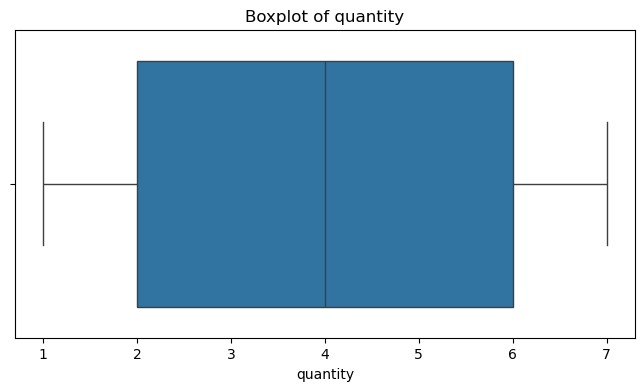

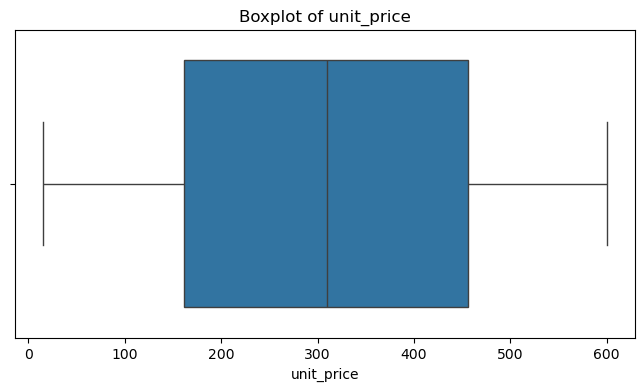

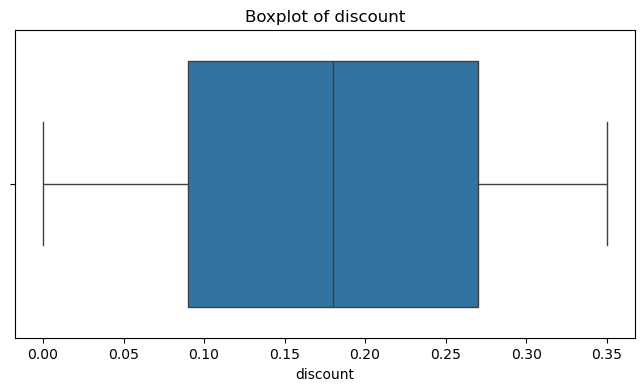

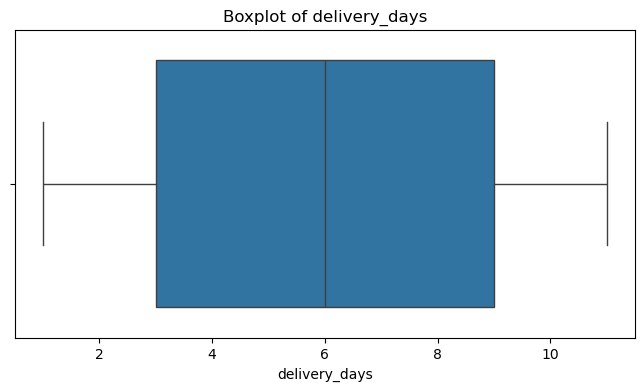

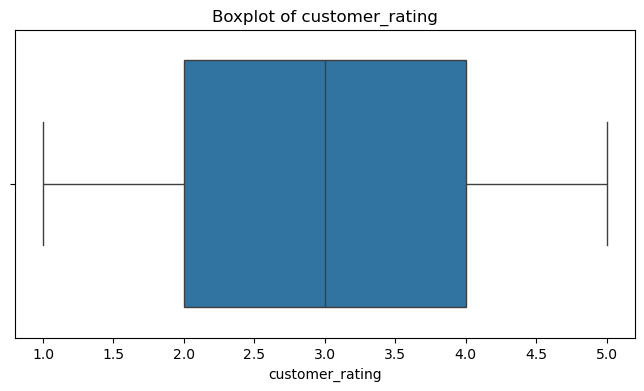

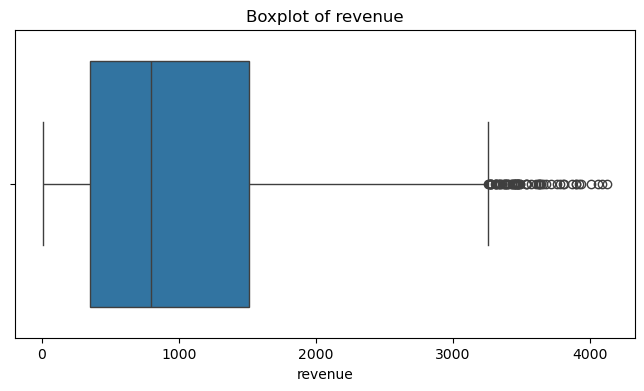

In [32]:
columns = ['quantity','unit_price','discount','delivery_days','customer_rating','revenue']
for col in columns:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=sales_data[col])
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.show()

In [33]:
sales_data[sales_data.revenue>3200].head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
39,10040,2022-02-09,1474,Home,North,7,584.36,0.11,Card,6,1.3,3640.56
69,10070,2022-03-11,1241,Beauty,East,7,567.75,0.16,Card,1,4.5,3338.37
97,10098,2022-04-08,1702,Electronics,North,6,576.02,0.07,Card,8,3.6,3214.19
102,10103,2022-04-13,1201,Clothing,West,6,586.65,0.02,COD,8,4.1,3449.50
126,10127,2022-05-07,1379,Clothing,South,7,506.18,0.02,Wallet,7,2.9,3472.39


In [34]:
sales_data['calculated_revenue'] = sales_data.quantity * sales_data.unit_price * (1-sales_data.discount)
sales_data['calculated_revenue'] = sales_data['calculated_revenue'].round(2)

In [35]:
sales_data.loc[sales_data['revenue'] == sales_data['calculated_revenue']].sort_values(by="order_id" ).count()[0]

C:\Users\Dell\AppData\Local\Temp\ipykernel_25548\1737988109.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  sales_data.loc[sales_data['revenue'] == sales_data['calculated_revenue']].sort_values(by="order_id" ).count()[0]


np.int64(5000)

Since after recalculating revenue, the previous revenue and the current revenue are same so there is no data problem, outliers may arised due to high price product or large quantity orders.

In [36]:
sales_data[sales_data['revenue'] > 3300][['quantity','unit_price','product_category','revenue']]

,quantity,unit_price,product_category,revenue
39,7,584.36,Home,3640.56
69,7,567.75,Beauty,3338.37
102,6,586.65,Clothing,3449.50
126,7,506.18,Clothing,3472.39
157,7,571.07,Electronics,3917.54
178,7,598.63,Electronics,3394.23
241,7,550.20,Electronics,3427.75
256,7,507.39,Home,3445.18
321,7,585.43,Electronics,3893.11
369,7,529.25,Beauty,3630.66


In [37]:
    revenue_outliers = sales_data[sales_data['revenue']>3300]
    revenue_outliers['product_category'].value_counts()

product_category
Electronics    24
Clothing       15
Home           11
Beauty         10
Name: count, dtype: int64

In [38]:
sales_data.groupby('product_category')['revenue'].describe()

,count,mean,std,min,25%,50%,75%,max
product_category,,,,,,,,
Beauty,723.0,1059.281992,867.590231,20.94,331.585,821.64,1662.825,4005.93
Clothing,1531.0,1000.608570,806.210745,11.21,349.940,785.22,1477.230,3928.63
Electronics,1777.0,1029.768835,831.796825,13.26,365.670,796.49,1499.280,4119.33
Home,969.0,1013.502497,812.271060,13.01,348.350,802.83,1488.750,3640.56


In [39]:
revenue_outliers[['product_category','quantity','unit_price','discount','revenue']].sort_values('revenue',ascending = False)

,product_category,quantity,unit_price,discount,revenue
809,Electronics,7,594.42,0.01,4119.33
4883,Electronics,7,583.31,0.00,4083.17
2214,Electronics,7,591.15,0.02,4055.29
3101,Beauty,7,596.12,0.04,4005.93
3686,Clothing,7,578.59,0.03,3928.63
157,Electronics,7,571.07,0.02,3917.54
3349,Electronics,7,574.15,0.03,3898.48
321,Electronics,7,585.43,0.05,3893.11
661,Clothing,7,581.67,0.05,3868.11
4305,Beauty,7,555.09,0.02,3807.92


In [40]:
sales_data[sales_data['revenue'] < 3200][['quantity','unit_price','discount','product_category','revenue']]

,quantity,unit_price,discount,product_category,revenue
0,7,373.65,0.28,Beauty,1883.20
1,7,47.74,0.09,Clothing,304.10
2,3,311.28,0.31,Beauty,644.35
3,5,524.47,0.02,Electronics,2569.90
4,5,139.87,0.33,Clothing,468.56
...,...,...,...,...,...
4995,2,371.74,0.27,Clothing,542.74
4996,3,553.67,0.14,Beauty,1428.47
4997,3,77.22,0.24,Beauty,176.06
4998,4,138.41,0.21,Electronics,437.38


Here,High revenue can occur when customers purchase a large quantity (6-7) or when the product has a high unit price(500-600) while discount seems to be low, between 0 to 19%. The revenue values match the quantity, price, and discount, so they appear to be valid transactions. Therefore, I kept these outliers in the dataset.

### Finding the categories of product.

In [41]:
sales_data.product_category.unique()

array(['Beauty', 'Clothing', 'Electronics', 'Home'], dtype=object)

### What are the different payment methods?

In [42]:
sales_data.payment_method.unique()

array(['Wallet', 'Card', 'COD'], dtype=object)

### which region customers are ordering from?

In [43]:
sales_data.region.unique()

array(['South', 'East', 'West', 'North'], dtype=object)